# 00 · Shared code

**Group 16 · Camera-based obstacle detection for driver assistance · Part 2**

Every experiment notebook needs the same building blocks: loading the split, running a detector, the KITTI
evaluator, training loops and plots. They are written **once**, here, each with its explanation. Every code cell
below appends to `kitti_common.py`, and the experiment notebooks start with `from kitti_common import *`.
On Kaggle, this notebook's output (that file) is attached to every experiment notebook.

| Notebook | Experiment | Answers |
|---|---|---|
| 01 | E0: COCO-pretrained YOLOv8s, no KITTI training | RQ1 |
| 02 | E2: YOLOv8s trained on KITTI | RQ1, RQ2 |
| 03 | E3: Faster R-CNN trained on KITTI | RQ2 |
| 04 | E4: tuning YOLOv8s (image size, class imbalance, learning rate) | final settings |
| 05 | FINAL: the chosen settings, full training | all RQs |
| 06 | E5: FINAL's recipe on a random image-level split | RQ3 |
| 07 | E6 + E8: weather-augmented training, fog / rain / low-light tests | RQ4 |
| 08 | E7: speed on the laptop GPU, the deployed pipeline and demo | RQ2 |
| 09 | all results, comparisons and the answers to RQ1-RQ4 | all |

**Research questions**

* **RQ1** How much does training on KITTI improve detection over a detector pretrained only on general-purpose data?
* **RQ2** Which approach gives the best balance between accuracy and speed, and can it run in real time on a laptop GPU?
* **RQ3** How much does a random image-level split overestimate performance compared with a split by drive?
* **RQ4** How much does accuracy drop under simulated fog, rain and low light, and can training augmentation reduce the drop?

## 1. Settings, paths and constants

* **Classes** keep the order of Part 1 (class id = position in the list). The **primary metric** uses Car,
  Pedestrian and Cyclist, the three classes that matter most for a driver-assistance system.
* **Paths.** On Kaggle the data is copied to the session's fast local disk (`/kaggle/tmp/kitti`) and everything we
  keep (weights, results) goes to `/kaggle/working`, which Kaggle saves as the notebook output. Locally the project
  folder is used.
* `KITTI_SMOKE=1` turns on a quick pipeline test (5 % of the training images, 2 epochs, 80 evaluation images).
  Its numbers are meaningless; it only proves that every cell runs.

In [1]:
%%writefile kitti_common.py
"""Shared code for the KITTI obstacle-detection notebooks (Group 16, Part 2).
Generated by notebooks/00_common.ipynb: edit it there, not here."""
import json
import os
import random
import shutil
import time
import zipfile
import zlib
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

SEED = 42
CLASSES = ["Car", "Pedestrian", "Van", "Cyclist", "Truck", "Misc", "Tram", "Person_sitting"]
FOCUS = ["Car", "Pedestrian", "Cyclist"]          # primary-metric classes
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
SPLITS = ["train", "val", "test"]
KITTI_FOCAL_PX = 721.5                            # KITTI camera focal length (px), for the distance estimate

ON_KAGGLE = Path("/kaggle/input").exists()
SMOKE = os.environ.get("KITTI_SMOKE") == "1"

if ON_KAGGLE:
    OUT = Path("/kaggle/working")
    _tmp = Path("/kaggle/tmp") if Path("/kaggle/tmp").exists() else Path("/tmp")
    DATA, RUNS = _tmp / "kitti", _tmp / "runs"
else:
    OUT = Path(os.environ.get("KITTI_ROOT") or (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
    DATA, RUNS = OUT / "data", OUT / "runs"
RESULTS, WEIGHTS = OUT / "results", OUT / "weights"


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def exp_dir(exp_id):
    """results/<exp_id>/: everything one experiment produces (history, metrics, predictions, figures)."""
    d = RESULTS / exp_id
    (d / "figures").mkdir(parents=True, exist_ok=True)
    return d

Writing kitti_common.py


## 2. Data access

The split was made once (a separate preparation step) and published as the Kaggle dataset
[`kitti-drive-grouped-split`](https://www.kaggle.com/datasets/fizzazaitoonbsds2022/kitti-drive-grouped-split):
images and YOLO labels per split, the per-object tables, and the split lists. `prepare_data()` finds it, copies the
splits a notebook needs to local disk (many parallel readers, because the mounted input is slow per file) and writes
the YOLO dataset file `kitti.yaml`. It accepts both unpacked folders and the original zip files, so the same code runs
on Kaggle and on a laptop that downloaded only the test zip.

Tables (one row each): `images.csv` (image, size, drive, both split labels), `annotations.csv` (object: class, box,
occlusion, truncation, KITTI difficulty), `ignore_regions.csv` (DontCare boxes).

In [2]:
%%writefile -a kitti_common.py


def _walk_find(pred, root="/kaggle/input", max_depth=7):
    base = len(Path(root).parts)
    for r, dirs, files in os.walk(root):
        hit = pred(Path(r), files)
        if hit:
            return hit
        dirs[:] = [] if len(Path(r).parts) - base >= max_depth else \
            [d for d in dirs if not d.startswith(("images", "labels", "label_2")) and d not in SPLITS]


def find_dataset():
    """Root folder of the split dataset (the folder that holds tables/annotations.csv)."""
    if not ON_KAGGLE:
        return DATA
    return _walk_find(lambda r, f: r.parent if r.name == "tables" and "annotations.csv" in f else None)


def _copy_files(src, dst, workers=64):
    dst.mkdir(parents=True, exist_ok=True)
    entries = [e for e in os.scandir(src) if e.is_file()]
    cp = lambda e: (dst / e.name).exists() or shutil.copyfile(e.path, dst / e.name)
    with ThreadPoolExecutor(workers) as ex:
        list(tqdm(ex.map(cp, entries), total=len(entries), desc=f"copy {src.parent.name}/{src.name}", leave=False))


def _fetch_split(ds, kind, split):
    """Make DATA/<kind>/<split>/ exist (kind = images | labels) from a folder or a zip in the dataset."""
    dst = DATA / kind / split
    if dst.is_dir() and any(dst.iterdir()):
        return dst
    folders = [ds / f"{kind}_{split}" / kind / split, ds / f"{kind}_yolo" / kind / split, ds / kind / split]
    zips = [ds / f"{kind}_{split}.zip", ds / f"{kind}_yolo.zip"]
    for f in folders:
        if f.is_dir() and f.resolve() != dst.resolve():
            _copy_files(f, dst)
            return dst
    for z in zips:
        if z.exists():
            with zipfile.ZipFile(z) as zf:
                members = [m for m in zf.namelist() if m.startswith(f"{kind}/{split}/")]
                for m in tqdm(members, desc=f"unzip {z.name} ({split})", leave=False):
                    zf.extract(m, DATA)
            return dst
    raise FileNotFoundError(f"{kind}/{split} not found in {ds}")


def write_yaml(root=DATA, train="images/train", val="images/val", test="images/test", name="kitti.yaml"):
    import yaml
    cfg = {"path": str(Path(root).resolve()), "train": train, "val": val, "test": test,
           "names": {i: c for i, c in enumerate(CLASSES)}}
    with open(Path(root) / name, "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return Path(root) / name


def load_tables():
    """(images, annotations, ignore_regions); image ids kept as 6-digit strings."""
    kw = dict(dtype={"image_id": str})
    t = DATA / "tables"
    return (pd.read_csv(t / "images.csv", **kw), pd.read_csv(t / "annotations.csv", **kw),
            pd.read_csv(t / "ignore_regions.csv", **kw))


def prepare_data(splits=SPLITS):
    """Copy the requested splits (images + YOLO labels) and the tables to DATA; write kitti.yaml."""
    ds = find_dataset()
    assert ds is not None, "attach the dataset fizzazaitoonbsds2022/kitti-drive-grouped-split"
    DATA.mkdir(parents=True, exist_ok=True)
    for sub in ["tables", "splits"]:
        if (ds / sub).is_dir() and (ds / sub).resolve() != (DATA / sub).resolve():
            shutil.copytree(ds / sub, DATA / sub, dirs_exist_ok=True)
    for s in splits:
        for kind in ["images", "labels"]:
            _fetch_split(ds, kind, s)
    for s in SPLITS:                                  # random-split lists (RQ3), relative to DATA
        if (ds / f"random_{s}.txt").exists() and ds.resolve() != DATA.resolve():
            shutil.copy(ds / f"random_{s}.txt", DATA / f"random_{s}.txt")
    write_yaml()
    tables = load_tables()
    print(f"data ready in {DATA}: " + ", ".join(f"{s} {len(list((DATA / 'images' / s).glob('*.png')))}" for s in splits))
    return tables


def split_ids(images, split, kind="grouped"):
    """Image ids of one split. In a smoke test, evaluation splits are cut to 80 images."""
    ids = images.loc[images[f"split_{kind}"] == split, "image_id"].tolist()
    return ids[:80] if (SMOKE and split != "train") else ids


def image_paths(ids, split=None, images=None, img_dir=None):
    """Paths of the given images. Grouped split: DATA/images/<split>/. Random split: look each image's folder up."""
    if img_dir is not None:
        return [Path(img_dir) / f"{i}.png" for i in ids]
    if split is not None:
        return [DATA / "images" / split / f"{i}.png" for i in ids]
    folder = dict(zip(images.image_id, images.split_grouped))
    return [DATA / "images" / folder[i] / f"{i}.png" for i in ids]

Appending to kitti_common.py


## 3. The KITTI evaluator

One evaluator scores every model (YOLO, Faster R-CNN, the COCO baseline), so the comparison is fair. We wrote it
ourselves because the libraries' built-in metrics do not follow the KITTI rules:

* **Difficulty.** A ground-truth object counts at *Moderate* only if its box is at least 25 px high, it is at most
  partly occluded and at most 30 % truncated. Objects that fail are *ignored* (neither found nor missed).
* **Neighbour classes.** A detection of a Van matched to a "Car" label is ignored, not a false positive (KITTI rule;
  same for Person_sitting vs Pedestrian).
* **DontCare.** A detection lying at least 50 % inside a DontCare region is ignored: those regions contain
  unlabelled objects, so a detection there is not an error.
* **AP|R40.** For each class, detections are sorted by score and matched greedily (IoU >= 0.5). AP is the mean of
  the best precision at 40 recall levels (1/40 ... 1), KITTI's official interpolation.

**Primary metric:** mean AP@0.5 of Car, Pedestrian and Cyclist at Moderate difficulty (`primary_mAP50_mod`).
We also report Easy and Hard, AP@0.7 for Car (KITTI's official Car threshold), mAP@0.5 over all 8 classes and the
COCO-style mAP@0.5:0.95.

In [3]:
%%writefile -a kitti_common.py


DIFFICULTY = {"easy": (40, 0, 0.15), "moderate": (25, 1, 0.30), "hard": (25, 2, 0.50), "all": (0, 3, 1.00)}
NEIGHBOUR = {"Car": ["Van"], "Pedestrian": ["Person_sitting"]}
R40 = np.linspace(1 / 40, 1, 40)
CIDX = {c: i for i, c in enumerate(CLASSES)}


def iou_matrix(a, b):
    """IoU between boxes a (N,4) and b (M,4) in x1,y1,x2,y2."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def inside_fraction(dets, regions):
    """Fraction of each detection's area covered by its most-overlapping DontCare region."""
    if len(dets) == 0 or len(regions) == 0:
        return np.zeros(len(dets))
    ix1 = np.maximum(dets[:, None, 0], regions[None, :, 0]); iy1 = np.maximum(dets[:, None, 1], regions[None, :, 1])
    ix2 = np.minimum(dets[:, None, 2], regions[None, :, 2]); iy2 = np.minimum(dets[:, None, 3], regions[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area = (dets[:, 2] - dets[:, 0]) * (dets[:, 3] - dets[:, 1])
    return (inter / (area[:, None] + 1e-9)).max(axis=1)


def ap_r40(scores, tp, n_pos):
    """KITTI 40-recall-point interpolated AP, plus the precision / recall curve."""
    if n_pos == 0:
        return np.nan, np.array([]), np.array([])
    if len(scores) == 0:
        return 0.0, np.array([0.0]), np.array([0.0])
    order = np.argsort(-scores, kind="stable")
    tp = tp[order]
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec = ctp / n_pos
    prec = ctp / np.maximum(ctp + cfp, 1e-9)
    env = np.maximum.accumulate(prec[::-1])[::-1]
    idx = np.searchsorted(rec, R40, side="left")
    ap = np.where(idx < len(env), env[np.minimum(idx, len(env) - 1)], 0.0).mean()
    return float(ap), prec, rec


def _pack_preds(preds):
    p = preds[preds["type"].isin(CIDX)]
    return {k: (g[["x1", "y1", "x2", "y2"]].to_numpy(float), g["type"].map(CIDX).to_numpy(int),
                g["score"].to_numpy(float)) for k, g in p.groupby("image_id")}


class Evaluator:
    """Build once per image set (ground truth indexed per image), then score any set of predictions."""

    def __init__(self, ann, ignore_regions, image_ids):
        self.image_ids = [str(i).zfill(6) for i in image_ids]
        ids = set(self.image_ids)
        ann = ann[ann["image_id"].isin(ids)]
        ign = ignore_regions[ignore_regions["image_id"].isin(ids)]
        self.gt = {k: (g[["x1", "y1", "x2", "y2"]].to_numpy(float), g["type"].map(CIDX).to_numpy(int),
                       g["occluded"].to_numpy(int), g["truncated"].to_numpy(float)) for k, g in ann.groupby("image_id")}
        self.dc = {k: g[["x1", "y1", "x2", "y2"]].to_numpy(float) for k, g in ign.groupby("image_id")}

    def _gt_for(self, image_id, ci, diff):
        g = self.gt.get(image_id)
        if g is None:
            return np.zeros((0, 4)), np.zeros(0, bool)
        boxes, cls, occ, trunc = g
        min_h, max_occ, max_trunc = DIFFICULTY[diff]
        same = cls == ci
        neigh = np.isin(cls, [CIDX[n] for n in NEIGHBOUR.get(CLASSES[ci], [])])
        h = boxes[:, 3] - boxes[:, 1]
        valid = same & (h >= min_h) & (occ <= max_occ) & (trunc <= max_trunc)
        keep = same | neigh
        return boxes[keep], valid[keep]

    def match_class(self, packed, cls, diff="moderate", iou_thr=0.5):
        """Scores and TP flags of the non-ignored detections of one class, and the number of valid GT objects."""
        ci, min_h = CIDX[cls], DIFFICULTY[diff][0]
        all_scores, all_tp, n_pos = [], [], 0
        empty = np.zeros((0, 4))
        for image_id in self.image_ids:
            gt_boxes, is_valid = self._gt_for(image_id, ci, diff)
            n_pos += int(is_valid.sum())
            p = packed.get(image_id)
            if p is None:
                continue
            m = p[1] == ci
            if not m.any():
                continue
            boxes, scores = p[0][m], p[2][m]
            o = np.argsort(-scores, kind="stable")
            boxes, scores = boxes[o], scores[o]
            ious = iou_matrix(boxes, gt_boxes)
            dc_frac = inside_fraction(boxes, self.dc.get(image_id, empty))
            small = (boxes[:, 3] - boxes[:, 1]) < min_h
            used = np.zeros(len(gt_boxes), bool)
            for j in range(len(boxes)):
                if len(gt_boxes):
                    hit = ious[j] >= iou_thr
                    cand = np.flatnonzero(is_valid & ~used & hit)
                    if len(cand):
                        used[cand[np.argmax(ious[j, cand])]] = True
                        all_scores.append(scores[j]); all_tp.append(1.0)
                        continue
                    if (~is_valid & hit).any():
                        continue                                   # matched an ignored object
                if small[j] or dc_frac[j] >= 0.5:
                    continue                                       # too small for this difficulty / in DontCare
                all_scores.append(scores[j]); all_tp.append(0.0)   # false positive
        return np.array(all_scores, float), np.array(all_tp, float), n_pos

    def evaluate(self, preds, classes=CLASSES, difficulties=("easy", "moderate", "hard", "all"),
                 iou_thrs=(0.5,), op_conf=0.25, packed=None):
        """One row per (class, difficulty, IoU): AP, #GT, recall / precision at the operating threshold."""
        packed = packed if packed is not None else _pack_preds(preds)
        rows = []
        for cls in classes:
            for diff in difficulties:
                for thr in iou_thrs:
                    s, tp, n_pos = self.match_class(packed, cls, diff, thr)
                    ap, prec, rec = ap_r40(s, tp, n_pos)
                    keep = s >= op_conf
                    rows.append({"class": cls, "difficulty": diff, "iou": round(float(thr), 2), "AP": ap,
                                 "n_gt": n_pos, "n_det": len(s),
                                 "recall_max": float(rec.max()) if (len(rec) and n_pos) else np.nan,
                                 "recall_op": float(tp[keep].sum() / n_pos) if n_pos else np.nan,
                                 "precision_op": float(tp[keep].mean()) if keep.any() else np.nan})
        return pd.DataFrame(rows)

    def pr_curve(self, preds, cls, diff="moderate", iou_thr=0.5):
        s, tp, n_pos = self.match_class(_pack_preds(preds), cls, diff, iou_thr)
        return ap_r40(s, tp, n_pos)

    def summary(self, preds, with_coco_range=True):
        """Headline numbers (dict) and the full per-class table."""
        packed = _pack_preds(preds)
        t = self.evaluate(preds, iou_thrs=(0.5, 0.7), packed=packed)
        a50 = t[t.iou == 0.5].set_index(["class", "difficulty"])
        a70 = t[t.iou == 0.7].set_index(["class", "difficulty"])
        out = {}
        for c in FOCUS:
            for d in ["easy", "moderate", "hard"]:
                out[f"AP50_{c}_{d}"] = a50.loc[(c, d), "AP"]
            out[f"recall_{c}_mod"] = a50.loc[(c, "moderate"), "recall_op"]
        out["primary_mAP50_mod"] = np.nanmean([out[f"AP50_{c}_moderate"] for c in FOCUS])
        out["mAP50_easy"] = np.nanmean([out[f"AP50_{c}_easy"] for c in FOCUS])
        out["mAP50_hard"] = np.nanmean([out[f"AP50_{c}_hard"] for c in FOCUS])
        out["mAP50_all8"] = np.nanmean([a50.loc[(c, "all"), "AP"] for c in CLASSES])
        out["AP70_Car_mod"] = a70.loc[("Car", "moderate"), "AP"]
        if with_coco_range:
            thr = np.round(np.arange(0.5, 0.96, 0.05), 2)
            r = self.evaluate(preds, difficulties=("all",), iou_thrs=thr, packed=packed)
            out["mAP50_95_all8"] = float(r.groupby("iou")["AP"].mean().mean())
        return {k: float(v) for k, v in out.items()}, t


def gt_as_predictions(ann, image_ids):
    """Sanity check: the ground truth fed back as predictions must score AP = 1."""
    g = ann[ann["image_id"].isin(set(image_ids))][["image_id", "type", "x1", "y1", "x2", "y2"]].copy()
    g["score"] = 1.0
    return g

Appending to kitti_common.py


## 4. Running the detectors

Every model returns its detections in the same table (`image_id, type, x1, y1, x2, y2, score`), so the evaluator, the
speed test and the app treat them identically. Detections are kept down to score 0.001: AP needs the whole
precision-recall curve, not only the confident boxes.

**COCO baseline (E0).** COCO has no Van, Misc or Person_sitting, so the baseline can never find them. COCO *person*
maps to Pedestrian and *bicycle* to Cyclist (COCO labels the rider and the bike separately, so this mapping is weak
on purpose: it shows what a general-purpose model gives without KITTI training).

In [4]:
%%writefile -a kitti_common.py


COCO_TO_KITTI = {2: "Car", 7: "Truck", 0: "Pedestrian", 1: "Cyclist", 6: "Tram"}
COLUMNS = ["image_id", "type", "x1", "y1", "x2", "y2", "score"]


def yolo_predict(model, paths, imgsz=640, conf=0.001, iou=0.6, half=True, max_det=100, class_map=None,
                 batch=16, desc="predict"):
    """model: ultralytics.YOLO or a weights path. class_map: {model class id: KITTI name} (COCO baseline only)."""
    from ultralytics import YOLO
    if not hasattr(model, "predict"):
        model = YOLO(str(model))
    half = half and torch.cuda.is_available()
    rows, paths = [], [str(p) for p in paths]
    for i in tqdm(range(0, len(paths), batch), desc=desc):
        for r in model.predict(paths[i:i + batch], imgsz=imgsz, conf=conf, iou=iou,
                               quantize="fp16" if half else None, max_det=max_det, verbose=False):
            b = r.boxes
            if b is None or len(b) == 0:
                continue
            xyxy, sc, cl = b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)
            img_id = Path(r.path).stem
            for (x1, y1, x2, y2), s, c in zip(xyxy, sc, cl):
                name = class_map.get(c) if class_map is not None else CLASSES[c]
                if name is not None:
                    rows.append((img_id, name, x1, y1, x2, y2, s))
    return pd.DataFrame(rows, columns=COLUMNS)


def build_frcnn(pretrained=True, score_thresh=0.001, detections_per_img=100):
    """torchvision Faster R-CNN (ResNet-50 FPN, COCO weights) with a new box head for 8 classes + background."""
    from torchvision.models import detection as D
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    m = D.fasterrcnn_resnet50_fpn(weights="DEFAULT" if pretrained else None, box_score_thresh=score_thresh,
                                  box_detections_per_img=detections_per_img)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(CLASSES) + 1)
    return m


def load_frcnn(weights, device=None):
    ckpt = torch.load(weights, map_location="cpu", weights_only=False)
    m = build_frcnn(pretrained=False)
    m.load_state_dict(ckpt["model"] if "model" in ckpt else ckpt)
    return m.to(device or ("cuda" if torch.cuda.is_available() else "cpu")).eval()


def read_rgb(path):
    from torchvision.io import read_image, ImageReadMode
    return read_image(str(path), ImageReadMode.RGB).float() / 255.0


@torch.no_grad()
def frcnn_predict(model, paths, batch=8, half=True, desc="predict"):
    if not hasattr(model, "roi_heads"):
        model = load_frcnn(model)
    device = next(model.parameters()).device
    amp = half and device.type == "cuda"
    rows, paths = [], [Path(p) for p in paths]
    for i in tqdm(range(0, len(paths), batch), desc=desc):
        chunk = paths[i:i + batch]
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            out = model([read_rgb(p).to(device) for p in chunk])
        for p, o in zip(chunk, out):
            for (x1, y1, x2, y2), s, l in zip(o["boxes"].float().cpu().numpy(), o["scores"].float().cpu().numpy(),
                                              o["labels"].cpu().numpy()):
                if l >= 1:
                    rows.append((p.stem, CLASSES[l - 1], x1, y1, x2, y2, s))
    return pd.DataFrame(rows, columns=COLUMNS)


def predict(kind, weights, paths, imgsz=640, class_map=None, desc="predict"):
    """kind = 'yolo' | 'frcnn'."""
    if kind == "frcnn":
        return frcnn_predict(weights, paths, desc=desc)
    return yolo_predict(weights, paths, imgsz=imgsz, class_map=class_map, desc=desc)

Appending to kitti_common.py


## 5. Class imbalance: repeat-factor sampling (RFS)

KITTI is dominated by cars (about 70 % of all objects); cyclists, trams and seated persons are rare. RFS
(Gupta et al., LVIS 2019) shows images that contain rare classes more often per epoch:

* for class *c*, `f_c` = fraction of **training** images that contain it; class repeat factor `r_c = max(1, sqrt(0.3 / f_c))`;
* an image is repeated `max(r_c)` over the classes it contains (fractional parts by random rounding, seed 42).

Ultralytics accepts a text file of image paths as the training set, so a repeated path simply means the image is
seen more often. Validation and test are never oversampled.

In [5]:
%%writefile -a kitti_common.py


def repeat_factors(ann_train, train_ids, t=0.3):
    presence = (pd.crosstab(ann_train["image_id"], ann_train["type"])
                  .reindex(index=train_ids, columns=CLASSES, fill_value=0) > 0)
    img_frac = presence.mean(axis=0)
    class_r = np.maximum(1.0, np.sqrt(t / img_frac.clip(lower=1e-12)))
    img_r = (presence * class_r).max(axis=1).clip(lower=1.0)
    return img_r, pd.DataFrame({"img_fraction": img_frac, "class_repeat": class_r})


def write_rfs_list(tables, root=DATA, kind="grouped", name="train_rfs.txt"):
    """Oversampled training list + its YOLO yaml. Returns (yaml path, per-class table, images per epoch)."""
    images, ann, _ = tables
    tr = split_ids(images, "train", kind)
    img_r, table = repeat_factors(ann[ann.image_id.isin(set(tr))], tr)
    rng = np.random.default_rng(SEED)
    reps = np.floor(img_r.values).astype(int) + (rng.random(len(img_r)) < img_r.values % 1).astype(int)
    paths = image_paths(img_r.index, images=images) if kind == "random" else         image_paths(img_r.index, img_dir=Path(root) / "images" / "train")
    lines = [os.path.abspath(p) for p, k in zip(paths, reps) for _ in range(k)]
    rng.shuffle(lines)
    (Path(root) / name).write_text("\n".join(lines) + "\n")
    val = "random_val.txt" if kind == "random" else "images/val"
    test = "random_test.txt" if kind == "random" else "images/test"
    y = write_yaml(root, train=name, val=val, test=test, name=name.replace(".txt", ".yaml"))
    print(f"RFS: {len(tr)} training images -> {len(lines)} per epoch")
    return y, table, len(lines)

Appending to kitti_common.py


## 6. Simulated weather (RQ4)

KITTI was recorded in clear daylight, so bad weather is simulated. Two **independent** implementations are used on
purpose:

* **Test corruptions** (`corrupt`): our own OpenCV / NumPy code, 3 severities each, seeded per image so every model
  sees exactly the same corrupted test images.
  * *fog*: atmospheric scattering `I = J·t + A·(1-t)` with `t = exp(-β·depth)`; depth is approximated as largest at
    the horizon and smaller towards the bottom of the image (the road close to the car);
  * *rain*: motion-blurred streaks over a darker, slightly blurred scene;
  * *low light*: gamma darkening, lower exposure and signal-dependent sensor noise.
* **Training augmentation** for E6 (`weather_train_transform`): Albumentations' RandomFog / RandomRain / gamma and
  noise, applied offline to 50 % of the training images.

If the test effects came from the same code as the training augmentation, the model could learn that generator's
artefacts and the robustness gain would be overstated. Labels are unchanged: weather does not move objects.

In [6]:
%%writefile -a kitti_common.py


WEATHER = ["fog", "rain", "low_light"]
SEVERITIES = [1, 2, 3]


def _rng(image_id, kind, severity):
    return np.random.default_rng(zlib.crc32(f"{image_id}|{kind}|{severity}|0".encode()))


def _fog(img, severity, rng):
    import cv2
    beta = [0.9, 1.6, 2.6][severity - 1]
    h, w = img.shape[:2]
    y = np.linspace(0, 1, h)[:, None]
    depth = np.clip(1.0 - 1.6 * np.clip(y - 0.45, 0, None), 0.25, 1.0) * np.ones((1, w))
    noise = cv2.GaussianBlur(rng.normal(0, 1, (h // 8 + 1, w // 8 + 1)).astype(np.float32), (0, 0), 3)
    noise = cv2.resize(noise, (w, h)) * 0.12
    t = np.exp(-beta * np.clip(depth + noise, 0.1, 1.2))[..., None]
    out = img.astype(np.float32) / 255.0 * t + rng.uniform(0.78, 0.88) * (1 - t)
    return np.clip(out * 255, 0, 255).astype(np.uint8)


def _rain(img, severity, rng):
    import cv2
    n, length, dim = [400, 1100, 2400][severity - 1], [10, 16, 24][severity - 1], [0.88, 0.78, 0.68][severity - 1]
    h, w = img.shape[:2]
    angle = np.deg2rad(rng.uniform(-15, 15))
    layer = np.zeros((h, w), np.float32)
    dx, dy = int(length * np.sin(angle)), int(length * np.cos(angle))
    for x, y_ in zip(rng.integers(0, w, n), rng.integers(0, h, n)):
        cv2.line(layer, (int(x), int(y_)), (int(x + dx), int(y_ + dy)), float(rng.uniform(0.5, 1.0)), 1)
    layer = cv2.blur(layer, (3, 3))[..., None]
    base = cv2.GaussianBlur(img, (0, 0), [0.6, 1.0, 1.4][severity - 1]).astype(np.float32) * dim
    return np.clip(base * (1 - 0.6 * layer) + 210 * 0.6 * layer, 0, 255).astype(np.uint8)


def _low_light(img, severity, rng):
    gamma, gain, sigma = [1.6, 2.1, 2.6][severity - 1], [0.55, 0.38, 0.25][severity - 1], [0.012, 0.022, 0.035][severity - 1]
    x = (img.astype(np.float32) / 255.0) ** gamma * gain
    x = x + rng.normal(0, 1, x.shape).astype(np.float32) * (sigma + 0.5 * sigma * np.sqrt(x))
    return np.clip(x * 255, 0, 255).astype(np.uint8)


def corrupt(img_bgr, kind, severity, image_id="0"):
    """Deterministic test-time corruption of one BGR image (severity 0 = unchanged)."""
    if severity == 0:
        return img_bgr
    return {"fog": _fog, "rain": _rain, "low_light": _low_light}[kind](img_bgr, severity, _rng(image_id, kind, severity))


def build_corrupted_test(ids, out_root=None):
    """DATA/corrupted/<kind>_s<severity>/<id>.png for every test image."""
    import cv2
    out_root = Path(out_root or DATA / "corrupted")

    def one(job):
        kind, s, i = job
        dst = out_root / f"{kind}_s{s}" / f"{i}.png"
        if not dst.exists():
            img = cv2.imread(str(DATA / "images" / "test" / f"{i}.png"))
            cv2.imwrite(str(dst), corrupt(img, kind, s, i), [cv2.IMWRITE_PNG_COMPRESSION, 1])

    jobs = [(k, s, i) for k in WEATHER for s in SEVERITIES for i in ids]
    for k in WEATHER:
        for s in SEVERITIES:
            (out_root / f"{k}_s{s}").mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(8) as ex:
        list(tqdm(ex.map(one, jobs), total=len(jobs), desc="corrupted test sets"))
    return out_root


def weather_train_transform():
    import albumentations as A
    return A.OneOf([
        A.RandomFog(fog_coef_range=(0.2, 0.6), alpha_coef=0.08, p=1.0),
        A.RandomRain(slant_range=(-12, 12), drop_length=18, blur_value=5, brightness_coefficient=0.75,
                     rain_type="drizzle", p=1.0),
        A.Compose([A.RandomGamma(gamma_limit=(150, 260), p=1.0),
                   A.RandomBrightnessContrast(brightness_limit=(-0.45, -0.2), contrast_limit=(-0.2, 0.0), p=1.0),
                   A.GaussNoise(std_range=(0.02, 0.06), p=1.0)], p=1.0),
    ], p=1.0)


def build_weather_train_set(train_ids, fraction=0.5, out=None):
    """Copy of the grouped YOLO dataset in which `fraction` of the TRAIN images are weather-augmented.
    Validation and test stay clean; labels are shared."""
    import cv2
    out = Path(out or DATA.parent / "kitti_weather")
    random.seed(SEED); np.random.seed(SEED)
    chosen = set(np.random.default_rng(SEED).choice(train_ids, int(len(train_ids) * fraction), replace=False))
    tf = weather_train_transform()
    (out / "images" / "train").mkdir(parents=True, exist_ok=True)
    (out / "labels").mkdir(parents=True, exist_ok=True)
    for s in SPLITS:
        if not (out / "labels" / s).exists():
            shutil.copytree(DATA / "labels" / s, out / "labels" / s)
        if s != "train" and not (out / "images" / s).exists():
            os.symlink((DATA / "images" / s).resolve(), out / "images" / s, target_is_directory=True)
    for i in tqdm(train_ids, desc="weather-augmented train set"):
        src, dst = DATA / "images" / "train" / f"{i}.png", out / "images" / "train" / f"{i}.png"
        if dst.exists() or dst.is_symlink():
            continue
        if i in chosen:
            img = cv2.cvtColor(cv2.imread(str(src)), cv2.COLOR_BGR2RGB)
            cv2.imwrite(str(dst), cv2.cvtColor(tf(image=img)["image"], cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 1])
        else:
            os.symlink(src.resolve(), dst)
    return out, sorted(chosen)

Appending to kitti_common.py


## 7. Training

**YOLO (Ultralytics).** All YOLO runs share these settings; an experiment changes only what it is about.
SGD (lr 0.01, momentum 0.937), 3 warm-up epochs, linear learning-rate decay, mixed precision, Ultralytics'
default augmentation (mosaic, random scale / shift, horizontal flip, HSV colour jitter), images cached in RAM, seed 42.
**Early stopping:** training stops when the validation fitness (mAP@0.5:0.95) has not improved for 10 epochs and the
**best** epoch is kept, not the last one. Earlier runs peaked within the first few epochs and then over-fitted the
training drives, so longer training only cost GPU time.

Ultralytics logs, per epoch, the training and validation losses (box regression, classification, distribution focal
loss) and validation precision / recall / mAP; this history is saved as `results/<exp>/history.csv` and plotted.

**Faster R-CNN (torchvision).** Its own loop: SGD (lr 0.01, momentum 0.9, weight decay 1e-4), 500 warm-up iterations,
learning rate ×0.1 at 70 % and 90 % of training, mixed precision, horizontal flip + mild colour jitter. Each epoch
logs the training loss, the **validation loss** (same loss on validation images, no gradient) and the validation
primary metric; the checkpoint with the best validation primary metric is kept.

In [7]:
%%writefile -a kitti_common.py


YOLO_COMMON = dict(seed=SEED, optimizer="SGD", lr0=0.01, cos_lr=False, patience=10, workers=4, plots=True,
                   verbose=False, exist_ok=True, amp=True, cache="ram", device=0 if torch.cuda.is_available() else "cpu")
if SMOKE:
    YOLO_COMMON.update(fraction=0.05, cache=False)


def yolo_train(exp_id, model, data_yaml, imgsz=640, epochs=50, batch=16, **overrides):
    """Train, keep best.pt as weights/<exp_id>.pt, save the per-epoch history. Returns (weights, info dict)."""
    from ultralytics import YOLO
    cfg = {**YOLO_COMMON, **overrides}
    epochs = 2 if SMOKE else epochs
    print(f"training {exp_id}: {model}, up to {epochs} epochs, imgsz {imgsz}, batch {batch}, changes: {overrides or 'none'}")
    t0 = time.time()
    YOLO(model).train(data=str(data_yaml), imgsz=imgsz, epochs=epochs, batch=batch, project=str(RUNS), name=exp_id, **cfg)
    hours = (time.time() - t0) / 3600
    run, d = RUNS / exp_id, exp_dir(exp_id)
    WEIGHTS.mkdir(parents=True, exist_ok=True)
    shutil.copy(run / "weights" / "best.pt", WEIGHTS / f"{exp_id}.pt")
    hist = pd.read_csv(run / "results.csv")
    hist.columns = [c.strip() for c in hist.columns]
    hist.to_csv(d / "history.csv", index=False)
    for f in ["results.png", "labels.jpg", "train_batch0.jpg", "val_batch0_pred.jpg"]:
        if (run / f).exists():
            shutil.copy(run / f, d / "figures" / f"ultralytics_{f}")
    best = hist.loc[hist["metrics/mAP50-95(B)"].idxmax()]
    info = {"model": model, "imgsz": imgsz, "batch": batch, "max_epochs": epochs, "epochs_run": len(hist),
            "best_epoch": int(best["epoch"]), "train_hours": round(hours, 3), "settings": json.dumps(overrides),
            "data": Path(data_yaml).name, "ultralytics_val_mAP50": float(best["metrics/mAP50(B)"]),
            "ultralytics_val_mAP50_95": float(best["metrics/mAP50-95(B)"])}
    return WEIGHTS / f"{exp_id}.pt", info


class KittiDetDataset(torch.utils.data.Dataset):
    """Images + boxes for Faster R-CNN (boxes in pixel corners, labels 1..8; 0 is background)."""

    def __init__(self, ids, ann, split, train=False):
        self.ids, self.split, self.train = list(ids), split, train
        g = ann[ann["image_id"].isin(set(self.ids))]
        self.boxes = {k: v[["x1", "y1", "x2", "y2"]].to_numpy(np.float32) for k, v in g.groupby("image_id")}
        self.labels = {k: v["type"].map(CLASS_TO_ID).to_numpy(np.int64) + 1 for k, v in g.groupby("image_id")}
        if train:
            from torchvision.transforms import ColorJitter
            self.jitter = ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.02)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        iid = self.ids[i]
        img = read_rgb(DATA / "images" / self.split / f"{iid}.png")
        h, w = img.shape[1:]
        boxes = torch.from_numpy(self.boxes.get(iid, np.zeros((0, 4), np.float32)).copy())
        labels = torch.from_numpy(self.labels.get(iid, np.zeros(0, np.int64)).copy())
        boxes[:, 0::2] = boxes[:, 0::2].clamp(0, w)
        boxes[:, 1::2] = boxes[:, 1::2].clamp(0, h)
        keep = (boxes[:, 2] > boxes[:, 0] + 1) & (boxes[:, 3] > boxes[:, 1] + 1)
        boxes, labels = boxes[keep], labels[keep]
        if self.train:
            if torch.rand(1).item() < 0.5:
                img = img.flip(-1)
                boxes = boxes[:, [2, 1, 0, 3]] * torch.tensor([-1, 1, -1, 1]) + torch.tensor([w, 0, w, 0])
            img = self.jitter(img)
        return img, {"boxes": boxes, "labels": labels}


def _collate(batch):
    return tuple(zip(*batch))


def train_frcnn(exp_id, tables, epochs=10, batch=4, lr=0.01, workers=4):
    """Returns (weights, info dict); writes results/<exp_id>/history.csv after every epoch."""
    seed_everything()
    images, ann, ign = tables
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tr, va = split_ids(images, "train"), split_ids(images, "val")
    if SMOKE:
        tr, epochs = tr[:200], 2
    dl = torch.utils.data.DataLoader(KittiDetDataset(tr, ann, "train", train=True), batch_size=batch, shuffle=True,
                                     num_workers=workers, collate_fn=_collate, persistent_workers=workers > 0,
                                     generator=torch.Generator().manual_seed(SEED))
    dl_val = torch.utils.data.DataLoader(KittiDetDataset(va, ann, "val"), batch_size=batch, num_workers=workers,
                                         collate_fn=_collate)
    model = build_frcnn().to(device)
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=0.9, weight_decay=1e-4)
    iters, warm = len(dl) * epochs, min(500, len(dl))
    milestones = [int(0.7 * iters), int(0.9 * iters)]
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: min(1.0, (it + 1) / warm) * 0.1 ** sum(it >= m for m in milestones))
    scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")
    evaluator = Evaluator(ann, ign, va)
    va_paths = image_paths(va, "val")
    d, out_w = exp_dir(exp_id), WEIGHTS / f"{exp_id}.pt"
    WEIGHTS.mkdir(parents=True, exist_ok=True)
    history, best, t0 = [], -1.0, time.time()
    for ep in range(1, epochs + 1):
        model.train()
        sums = {}
        for imgs, tg in tqdm(dl, desc=f"epoch {ep}/{epochs} train"):
            imgs = [im.to(device, non_blocking=True) for im in imgs]
            tg = [{k: v.to(device) for k, v in t.items()} for t in tg]
            with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                parts = model(imgs, tg)
                loss = sum(parts.values())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            for k, v in parts.items():
                sums[k] = sums.get(k, 0.0) + v.item()
        row = {"epoch": ep, **{f"train/{k}": v / len(dl) for k, v in sums.items()}}
        row["train/loss"] = sum(v for k, v in row.items() if k.startswith("train/loss_"))
        vsums = {}                                       # validation loss: train-mode forward, no gradient
        with torch.no_grad():
            for imgs, tg in tqdm(dl_val, desc=f"epoch {ep}/{epochs} val loss", leave=False):
                imgs = [im.to(device) for im in imgs]
                tg = [{k: v.to(device) for k, v in t.items()} for t in tg]
                with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                    for k, v in model(imgs, tg).items():
                        vsums[k] = vsums.get(k, 0.0) + v.item()
        row.update({f"val/{k}": v / len(dl_val) for k, v in vsums.items()})
        row["val/loss"] = sum(v for k, v in row.items() if k.startswith("val/loss_"))
        model.eval()
        s, _ = evaluator.summary(frcnn_predict(model, va_paths, desc=f"epoch {ep}/{epochs} val mAP"), with_coco_range=False)
        row.update({"val/primary_mAP50_mod": s["primary_mAP50_mod"], "val/mAP50_all8": s["mAP50_all8"],
                    "lr": opt.param_groups[0]["lr"], "elapsed_h": (time.time() - t0) / 3600})
        if s["primary_mAP50_mod"] > best:
            best = s["primary_mAP50_mod"]
            torch.save({"model": model.state_dict(), "epoch": ep}, out_w)
        history.append(row)
        pd.DataFrame(history).to_csv(d / "history.csv", index=False)
        print(f"epoch {ep}: train loss {row['train/loss']:.3f} | val loss {row['val/loss']:.3f} | "
              f"val primary {row['val/primary_mAP50_mod']:.3f}")
    hist = pd.DataFrame(history)
    info = {"model": "fasterrcnn_resnet50_fpn (COCO)", "imgsz": "800/1333", "batch": batch, "max_epochs": epochs,
            "epochs_run": epochs, "best_epoch": int(hist.loc[hist["val/primary_mAP50_mod"].idxmax(), "epoch"]),
            "train_hours": round((time.time() - t0) / 3600, 3),
            "settings": json.dumps({"optimizer": "SGD", "lr": lr, "amp": True})}
    return out_w, info

Appending to kitti_common.py


## 8. Evaluation and the experiment record

`evaluate_model` runs a model on one image set, saves its detections (`results/<exp>/preds_<set>.parquet`, so later
notebooks can re-score without the GPU) and returns the headline numbers and the per-class table.

Every experiment writes **one record**, `results/<exp>/record.json`: what was trained, with which settings, how long
it took, its validation metrics and (for finished models) its test metrics. The results notebook collects all records
into `results/experiments.csv`. Model choices are made on **validation** only; each finished model is scored on the
**test** set exactly once, at the end of its notebook.

In [8]:
%%writefile -a kitti_common.py


def evaluate_model(exp_id, kind, weights, tables, split="val", split_kind="grouped", imgsz=640, class_map=None,
                   img_dir=None, tag=None):
    images, ann, ign = tables
    tag = tag or (split if split_kind == "grouped" else f"{split_kind}_{split}")
    ids = split_ids(images, split, split_kind)
    paths = image_paths(ids, images=images, img_dir=img_dir) if (split_kind == "random" and img_dir is None) \
        else image_paths(ids, split, img_dir=img_dir)
    preds = predict(kind, weights, paths, imgsz, class_map, desc=f"{exp_id} on {tag}")
    d = exp_dir(exp_id)
    p = preds.copy()
    for c in ["x1", "y1", "x2", "y2", "score"]:
        p[c] = p[c].astype(np.float32)
    p.to_parquet(d / f"preds_{tag}.parquet", index=False)
    summ, table = Evaluator(ann, ign, ids).summary(preds)
    table.to_csv(d / f"per_class_{tag}.csv", index=False)
    return summ, table, preds


def load_preds(path):
    df = pd.read_parquet(path)
    df["image_id"] = df["image_id"].astype(str).str.zfill(6)
    return df


def save_record(exp_id, description, rq, val=None, test=None, **info):
    """results/<exp_id>/record.json: one row of the experiment log."""
    rec = {"exp_id": exp_id, "description": description, "research_question": rq, **info,
           **{f"val_{k}": v for k, v in (val or {}).items()}, **{f"test_{k}": v for k, v in (test or {}).items()},
           "smoke_test": SMOKE, "logged_at": datetime.now().isoformat(timespec="seconds")}
    (exp_dir(exp_id) / "record.json").write_text(json.dumps(rec, indent=1, default=str))
    return rec


def load_record(exp_id, roots=None):
    for r in roots or [RESULTS]:
        p = Path(r) / exp_id / "record.json"
        if p.exists():
            return json.loads(p.read_text())
    return None


HEADLINE = {"primary_mAP50_mod": "Primary (Car/Ped/Cyc, Moderate)", "AP50_Car_moderate": "Car",
            "AP50_Pedestrian_moderate": "Pedestrian", "AP50_Cyclist_moderate": "Cyclist",
            "mAP50_easy": "Easy (3 classes)", "mAP50_hard": "Hard (3 classes)", "AP70_Car_mod": "Car AP@0.7",
            "mAP50_all8": "mAP@0.5, all 8 classes", "mAP50_95_all8": "mAP@0.5:0.95, all 8 classes"}


def headline(**sets):
    """Table of the headline metrics, one column per evaluation set, e.g. headline(val=s1, test=s2)."""
    return pd.DataFrame({name: {HEADLINE[k]: s.get(k, np.nan) for k in HEADLINE} for name, s in sets.items()}).round(3)


def find_kaggle_outputs(name):
    """On Kaggle: folders of attached notebook outputs that contain `name` (e.g. 'results')."""
    if not ON_KAGGLE:
        return []
    out = []
    for r, dirs, _ in os.walk("/kaggle/input"):
        if name in dirs:
            out.append(Path(r))
        dirs[:] = [d for d in dirs if d not in ("images", "labels", "label_2", "results", "weights") and d not in SPLITS]
    return out


def import_outputs(*exp_ids):
    """Copy results/<exp>/ and weights/<exp>.pt of finished experiments from attached notebook outputs."""
    for root in find_kaggle_outputs("results"):
        for e in exp_ids:
            if (root / "results" / e).is_dir() and not (RESULTS / e / "record.json").exists():
                shutil.copytree(root / "results" / e, RESULTS / e, dirs_exist_ok=True)
            w = root / "weights" / f"{e}.pt"
            if w.exists() and not (WEIGHTS / f"{e}.pt").exists():
                WEIGHTS.mkdir(parents=True, exist_ok=True)
                shutil.copy(w, WEIGHTS / f"{e}.pt")
        if (root / "results" / "final_config.json").exists() and not (RESULTS / "final_config.json").exists():
            RESULTS.mkdir(parents=True, exist_ok=True)
            shutil.copy(root / "results" / "final_config.json", RESULTS / "final_config.json")
    missing = [e for e in exp_ids if not (RESULTS / e / "record.json").exists()]
    print("imported:", [e for e in exp_ids if e not in missing], "| missing:", missing)

Appending to kitti_common.py


## 9. Plots

One colour per role, fixed everywhere: **training** curves blue, **validation** curves orange; the three focus
classes and the models each keep their own colour in every figure (a colour-blind-safe palette). Thin lines, light
grid, every figure also saved to `results/<exp>/figures/`.

In [9]:
%%writefile -a kitti_common.py


import matplotlib
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TRAIN_C, VAL_C = PALETTE[0], PALETTE[1]
CLASS_C = {c: PALETTE[i] for i, c in enumerate(FOCUS)}
MODEL_C = {"E0": "#8a8984", "E2": PALETTE[0], "E3": PALETTE[1], "FINAL": PALETTE[2], "E5": PALETTE[4],
           "E6": PALETTE[6]}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": "#8a8984",
                     "axes.titlesize": 11, "axes.axisbelow": True, "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 2,
                     "axes.prop_cycle": matplotlib.cycler(color=PALETTE)})


def _save(fig, exp_id, name):
    from matplotlib.ticker import MaxNLocator
    for a in fig.axes:
        if a.get_xlabel() == "epoch":
            a.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.tight_layout()
    fig.savefig(exp_dir(exp_id) / "figures" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


def plot_yolo_history(exp_id, hist=None):
    """Training vs validation loss (box, classification, DFL) and validation mAP per epoch."""
    h = hist if hist is not None else pd.read_csv(exp_dir(exp_id) / "history.csv")
    best = h.loc[h["metrics/mAP50-95(B)"].idxmax(), "epoch"]
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
    for a, (k, name) in zip(ax, [("box_loss", "box regression loss"), ("cls_loss", "classification loss"),
                                 ("dfl_loss", "distribution focal loss")]):
        a.plot(h.epoch, h[f"train/{k}"], color=TRAIN_C, label="train")
        a.plot(h.epoch, h[f"val/{k}"], color=VAL_C, label="validation")
        a.axvline(best, color="#8a8984", lw=1, ls="--")
        a.set_title(name); a.set_xlabel("epoch")
    ax[0].legend()
    ax[3].plot(h.epoch, h["metrics/mAP50(B)"], color=VAL_C, label="mAP@0.5")
    ax[3].plot(h.epoch, h["metrics/mAP50-95(B)"], color=VAL_C, ls=":", label="mAP@0.5:0.95")
    ax[3].axvline(best, color="#8a8984", lw=1, ls="--", label=f"best epoch ({best})")
    ax[3].set_title("validation mAP (Ultralytics, 8 classes)"); ax[3].set_xlabel("epoch"); ax[3].legend()
    fig.suptitle(f"{exp_id}: training history", x=0.01, ha="left", fontsize=12)
    _save(fig, exp_id, "history")


def plot_frcnn_history(exp_id, hist=None):
    h = hist if hist is not None else pd.read_csv(exp_dir(exp_id) / "history.csv")
    best = h.loc[h["val/primary_mAP50_mod"].idxmax(), "epoch"]
    parts = [("loss", "total loss"), ("loss_classifier", "box classification"), ("loss_box_reg", "box regression"),
             ("loss_objectness", "RPN objectness")]
    fig, ax = plt.subplots(1, 5, figsize=(19, 3.4))
    for a, (k, name) in zip(ax, parts):
        a.plot(h.epoch, h[f"train/{k}"], color=TRAIN_C, marker="o", ms=4, label="train")
        a.plot(h.epoch, h[f"val/{k}"], color=VAL_C, marker="o", ms=4, label="validation")
        a.axvline(best, color="#8a8984", lw=1, ls="--")
        a.set_title(name); a.set_xlabel("epoch")
    ax[0].legend()
    ax[4].plot(h.epoch, h["val/primary_mAP50_mod"], color=VAL_C, marker="o", ms=4, label="primary (KITTI)")
    ax[4].plot(h.epoch, h["val/mAP50_all8"], color=VAL_C, ls=":", marker="o", ms=4, label="mAP@0.5, 8 classes")
    ax[4].axvline(best, color="#8a8984", lw=1, ls="--", label=f"best epoch ({best})")
    ax[4].set_title("validation metrics"); ax[4].set_xlabel("epoch"); ax[4].legend()
    fig.suptitle(f"{exp_id}: training history", x=0.01, ha="left", fontsize=12)
    _save(fig, exp_id, "history")


def plot_per_class(exp_id, table, title):
    """AP@0.5 per focus class at Easy / Moderate / Hard, plus AP@0.5 of all 8 classes."""
    t = table[table.iou == 0.5]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
    diffs = ["easy", "moderate", "hard"]
    x = np.arange(len(diffs))
    for j, c in enumerate(FOCUS):
        v = [t[(t["class"] == c) & (t.difficulty == d)].AP.iloc[0] for d in diffs]
        bars = ax[0].bar(x + (j - 1) * 0.26, v, 0.24, color=CLASS_C[c], label=c)
        ax[0].bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
    ax[0].set_xticks(x, diffs); ax[0].set_ylim(0, 1.25); ax[0].set_yticks(np.arange(0, 1.01, 0.2))
    ax[0].set_ylabel("AP@0.5"); ax[0].legend(ncol=3, loc="upper center")
    ax[0].set_title("focus classes by KITTI difficulty")
    a = t[t.difficulty == "all"].set_index("class").reindex(CLASSES)
    bars = ax[1].barh(CLASSES[::-1], a.AP.values[::-1], color=TRAIN_C, height=0.6)
    ax[1].bar_label(bars, labels=[f"{v:.2f}  (n={int(n)})" for v, n in zip(a.AP.values[::-1], a.n_gt.values[::-1])],
                    fontsize=7, padding=3)
    ax[1].set_xlim(0, 1.25); ax[1].set_xlabel("AP@0.5 (all difficulties)"); ax[1].set_title("all 8 classes")
    fig.suptitle(f"{exp_id}: {title}", x=0.01, ha="left", fontsize=12)
    _save(fig, exp_id, f"per_class_{title.split()[0]}")


def plot_pr(exp_id, preds, tables, split="test", split_kind="grouped"):
    """Precision-recall curves (Moderate, IoU 0.5) of the focus classes."""
    images, ann, ign = tables
    ev = Evaluator(ann, ign, split_ids(images, split, split_kind))
    fig, ax = plt.subplots(figsize=(5.2, 4))
    for c in FOCUS:
        ap, prec, rec = ev.pr_curve(preds, c)
        if len(rec):
            env = np.maximum.accumulate(prec[::-1])[::-1]
            ax.plot(rec, env, color=CLASS_C[c], label=f"{c} (AP {ap:.2f})")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(loc="lower left")
    ax.set_title(f"{exp_id}: precision-recall on {split} (Moderate)")
    _save(fig, exp_id, f"pr_{split}")


def show_detections(exp_id, preds, tables, ids, split="test", conf=0.4, img_dir=None, name="examples"):
    """Ground truth (dashed white) and detections above `conf` (coloured by class) on a few images."""
    from PIL import Image
    images, ann, _ = tables
    fig, axes = plt.subplots(len(ids), 1, figsize=(13, 3.6 * len(ids)))
    for a, iid in zip(np.atleast_1d(axes), ids):
        a.imshow(Image.open(Path(img_dir or DATA / "images" / split) / f"{iid}.png"))
        for b in ann[ann.image_id == iid].itertuples():
            a.add_patch(plt.Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False, ec="white", lw=1, ls="--"))
        for b in preds[(preds.image_id == iid) & (preds.score >= conf)].itertuples():
            c = CLASS_C.get(b.type, PALETTE[3 + CLASSES.index(b.type) % 5])
            a.add_patch(plt.Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False, ec=c, lw=2))
            a.text(b.x1, b.y1 - 3, f"{b.type} {b.score:.2f}", color="white", fontsize=7,
                   bbox=dict(facecolor=c, edgecolor="none", pad=1))
        a.set_title(iid, loc="left"); a.axis("off"); a.grid(False)
    fig.suptitle(f"{exp_id}: detections (score >= {conf}) vs ground truth (dashed)", x=0.01, ha="left", fontsize=12)
    _save(fig, exp_id, name)


def ultralytics_test_report(exp_id, weights, imgsz, data_yaml=None, split="test"):
    """Ultralytics' own evaluation on the test split: confusion matrix and PR curve figures (cross-check)."""
    from ultralytics import YOLO
    from IPython.display import Image as IPImage, display
    r = YOLO(str(weights)).val(data=str(data_yaml or DATA / "kitti.yaml"), split=split, imgsz=imgsz, batch=16,
                               plots=True, project=str(RUNS), name=f"{exp_id}_{split}", exist_ok=True, verbose=False)
    run, d = RUNS / f"{exp_id}_{split}", exp_dir(exp_id)
    for f in ["confusion_matrix_normalized.png", "BoxPR_curve.png"]:
        if (run / f).exists():
            shutil.copy(run / f, d / "figures" / f"ultralytics_{split}_{f}")
    if (run / "confusion_matrix_normalized.png").exists():
        display(IPImage(filename=str(run / "confusion_matrix_normalized.png"), width=620))
    return {"ultralytics_mAP50": float(r.box.map50), "ultralytics_mAP50_95": float(r.box.map)}

Appending to kitti_common.py


## 10. Self-test

The module is imported and checked without a GPU: the evaluator must give AP = 1 when the ground truth is fed back
as predictions, and the weather corruptions are shown on one image.

In [10]:
import importlib, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import kitti_common as kc
importlib.reload(kc)
tables = kc.prepare_data(splits=["val"]) if kc.ON_KAGGLE or (kc.DATA / "tables").exists() else None
if tables is not None:
    images, ann, ign = tables
    ids = kc.split_ids(images, "val")
    summ, _ = kc.Evaluator(ann, ign, ids).summary(kc.gt_as_predictions(ann, ids))
    assert abs(summ["primary_mAP50_mod"] - 1) < 1e-9 and abs(summ["mAP50_all8"] - 1) < 1e-9, summ
    print("evaluator sanity check passed: ground truth scores AP = 1.0")
    print(images.groupby("split_grouped").agg(images=("image_id", "size"), drives=("drive", "nunique")))

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

data ready in /tmp/kitti: val 1239
evaluator sanity check passed: ground truth scores AP = 1.0
               images  drives
split_grouped                
test             1543       8
train            4699     119
val              1239      14


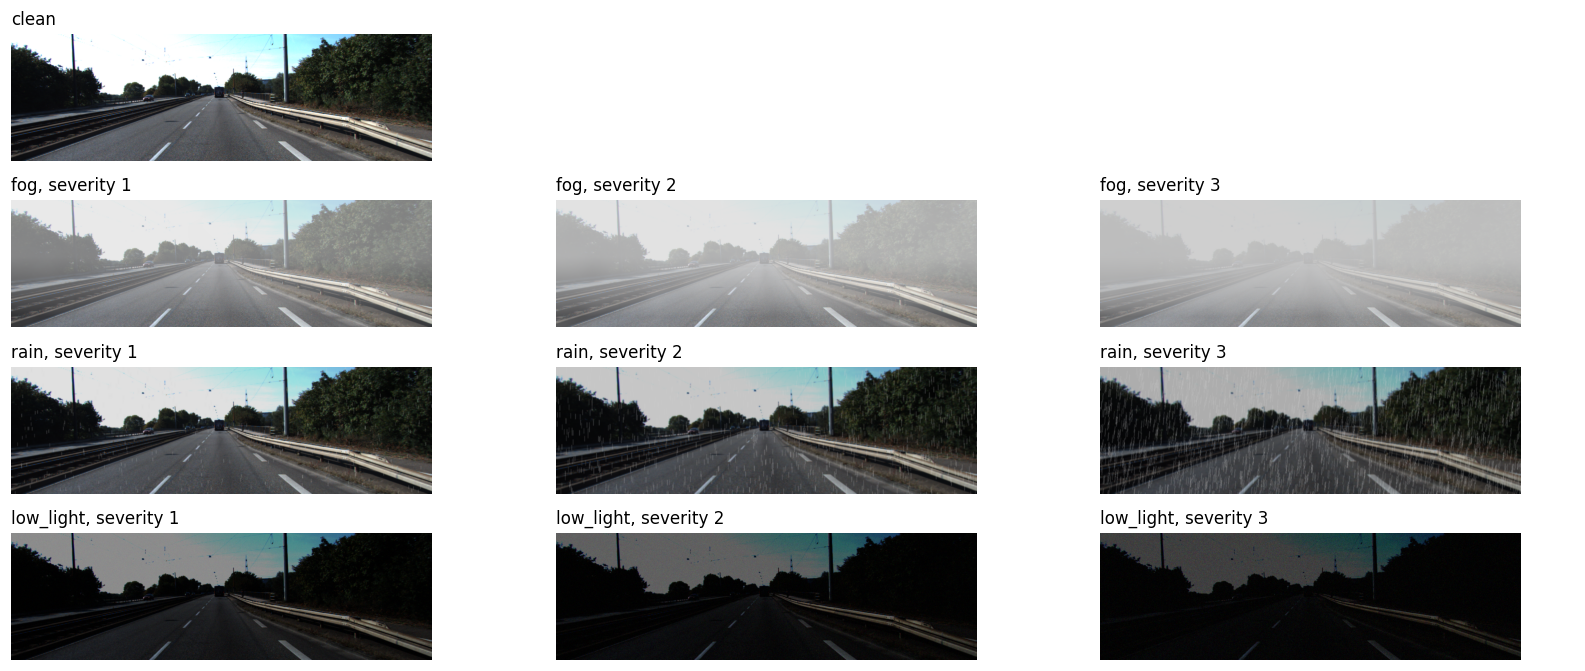

In [11]:
import cv2
import matplotlib.pyplot as plt
if tables is not None:
    iid = kc.split_ids(images, "val")[0]
    img = cv2.imread(str(kc.DATA / "images" / "val" / f"{iid}.png"))
    fig, ax = plt.subplots(4, 3, figsize=(15, 6.2))
    for a in ax.flat:
        a.axis("off")
    ax[0, 0].imshow(img[..., ::-1]); ax[0, 0].set_title("clean", loc="left")
    for r, kind in enumerate(kc.WEATHER, start=1):
        for c, s in enumerate(kc.SEVERITIES):
            ax[r, c].imshow(kc.corrupt(img, kind, s, iid)[..., ::-1]); ax[r, c].set_title(f"{kind}, severity {s}", loc="left")
    plt.tight_layout(); plt.show()